# Inside stage 4: SCC block moves, cycle by cycle

**How big are the components, how often do they move, and where does the gain
come from — measured, on the fly connectome.**

Stage 4 of the champion pipeline alternates two move classes for 77 cycles:

* a **block move** — decompose a contiguous stretch of the line into strongly
  connected components (SCCs), lay the components out in topological order, and
  recurse; correct by construction, it can never lose score;
* a **short sift** — 2 sweeps of the single-node exact-gain move from stage 3.

The main walkthrough (`champion_pipeline_walkthrough.ipynb`, section 7) shows stage 4
only from the outside: one score per cycle. This notebook opens one full run of the
stage and instruments every block the refiner touches.

### What is re-computed here, and what that means

The production run records do not contain block-level information, so this notebook
**re-runs stages 1–4 on this machine** to get it. Two honesty notes follow:

* **Stage 2 (the gradient phase) is not deterministic on Apple MPS**, so the stage-4
  *input* ordering built here differs slightly from the one inside the registered
  CUDA champion runs. Every number below describes **this run on this machine**; no
  champion claim is derived from any of them. The registered champion numbers live in
  `results/*.json` and `autoresearch/sota.json`.
* **Stage 4 itself is deterministic** — pure integer/NumPy arithmetic on the CPU, no
  RNG. Given the cached input ordering (`notebooks/outputs/stage4_input_rank.npy`,
  written on the first run), the entire trace below reproduces exactly, on any machine.

The instrumented refiner is asserted **bit-identical** to the library refiner
(`mfas.refine.scc_recursive`) on the real inputs of the first two cycles, so the
instrumentation demonstrably does not change what is being measured.

---

## 1. Setup and configuration

All champion hyperparameters are **imported from `mfas.experiments.H64`** — the
registered connectome champion — rather than retyped, so this notebook cannot drift
from the pipeline it claims to dissect. The cell asserts the values it expects.

In [1]:
"""Configuration and helpers. Run this cell first."""
import json
import pathlib
import sys
import time

import matplotlib.pyplot as plt
import numpy as np


def find_repo_root(start: pathlib.Path) -> pathlib.Path:
    """Walk upwards from `start` until a folder with results/ and experiments/ is found."""
    for candidate in [start, *start.parents]:
        if (candidate / "results").is_dir() and (candidate / "experiments").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository root from %s" % start)


ROOT = find_repo_root(pathlib.Path.cwd())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

# Champion constants come from the H64 module itself — the single source of truth.
from mfas.experiments import H64 as H64mod
from mfas.refine.scc_recursive import DEFAULT_SPLIT_FRACS

CONFIG = {
    "dataset": "connectome",
    "seed": 42,                       # logged for provenance; the pipeline never draws from it

    # ── Stage-2/3 champion constants (H64 = H42's stack with the ASYM surrogate).
    "epochs": H64mod._EPOCHS["connectome"],
    "sift_max_sweeps": H64mod._MAX_SWEEPS["connectome"],
    "sift_k_full": H64mod._K_FULL,
    "alpha": H64mod._ALPHA,

    # ── Stage-4 champion constants.
    "alt_cycles": H64mod._ALT_CYCLES["connectome"],
    "alt_sift_sweeps": H64mod._ALT_SIFT_SWEEPS["connectome"],
    "alt_k_full": H64mod._ALT_K_FULL,
    "min_block": H64mod._MIN_BLOCK,
    "split_fracs": tuple(DEFAULT_SPLIT_FRACS),

    # ── Instrumentation.
    "deep_cycles": [0, 1, 38, 76],    # cycles recorded block-by-block (first, second, mid, last)
    "equiv_check_cycles": [0, 1],     # cycles re-run through the library refiner and compared
    "pos_bins": 128,                  # position bins for the "where do moves happen" heatmap

    # ── Caches (written on the first run, re-used afterwards).
    "cache_input_rank": "notebooks/outputs/stage4_input_rank.npy",
    "cache_input_meta": "notebooks/outputs/stage4_input_meta.json",
    "cache_trace": "notebooks/outputs/stage4_inside_trace.npz",
    "cache_trace_meta": "notebooks/outputs/stage4_inside_meta.json",

    # ── The frozen-scorer parity anchor (CLAUDE.md "Oracle facts").
    "anchor_positions": "results/rocket_best_positions.npy",
    "anchor_score": 34_751_902,

    # ── Plot settings — same style and validated palette as the walkthrough
    #    (slots 1–5 of the project default; worst adjacent CVD separation dE 9.1).
    "dpi": 120,
    "figdir": "notebooks/outputs",
    "c_block": "#eda100",    # the block-move half of the alternation (stage 4's colour)
    "c_sift": "#1baf7a",     # the inner-sift half (stage 3's colour — it IS that move)
    "c_topo": "#2a78d6",     # a block that decomposed into >= 2 SCCs and was re-laid out
    "c_topo_still": "#b7d3f2",  # same event, but the topological layout changed nothing
    "c_split": "#eb6834",    # a block that was ONE SCC and had to be cut in half
    "ink": "#0b0b0b",
    "ink_soft": "#52514e",
    "grid": "#d9d8d4",
}

# The values this notebook was written against — fail loudly if the champion moves.
assert CONFIG["epochs"] == 20_000 and CONFIG["alt_cycles"] == 77
assert CONFIG["alt_sift_sweeps"] == 2 and CONFIG["alt_k_full"] == 2
assert CONFIG["min_block"] == 32 and CONFIG["alpha"] == 0.7
assert CONFIG["split_fracs"] == (0.5, 0.382, 0.618, 0.25, 0.75)

FIGDIR = ROOT / CONFIG["figdir"]
FIGDIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name: str) -> None:
    """Save a figure to notebooks/outputs/ and report where it went."""
    path = FIGDIR / name
    fig.savefig(path, dpi=CONFIG["dpi"], bbox_inches="tight", facecolor="white")
    print("saved:", path.relative_to(ROOT))


def style_axes(ax, *, ygrid: bool = True) -> None:
    """Apply the project's chart style: recessive grid, no top/right spines."""
    ax.set_axisbelow(True)
    if ygrid:
        ax.grid(axis="y", color=CONFIG["grid"], linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(CONFIG["grid"])
    ax.tick_params(colors=CONFIG["ink_soft"], labelsize=9)


plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.titlecolor": CONFIG["ink"],
    "axes.labelcolor": CONFIG["ink_soft"],
    "font.size": 10,
    "legend.frameon": False,
})

print("repository root:", ROOT)
print("champion constants: epochs=%d, alt_cycles=%d, min_block=%d, split_fracs=%s"
      % (CONFIG["epochs"], CONFIG["alt_cycles"], CONFIG["min_block"],
         CONFIG["split_fracs"]))

repository root: /Users/abed359/IdeaProjects/university/deeplearning_thesis/nn_backward_connections
champion constants: epochs=20000, alt_cycles=77, min_block=32, split_fracs=(0.5, 0.382, 0.618, 0.25, 0.75)


---

## 2. Load the graph, verify the frozen scorer

Before trusting any score below, the cell re-checks the project's parity anchor:
the frozen scorer applied to the committed best-position vector must return exactly
**34,751,902**. If that fails, nothing else in this notebook is meaningful.

In [2]:
"""Load the fly connectome and verify the scorer parity anchor."""
from mfas.io import load_dataset
from mfas.metrics import pct, score_from_order, score_from_positions

g = load_dataset(CONFIG["dataset"])
src_o = np.asarray(g.src)
tgt_o = np.asarray(g.tgt)
N = g.n_nodes
print(g)

anchor_pos = np.load(ROOT / CONFIG["anchor_positions"])
anchor = score_from_positions(anchor_pos, src_o, tgt_o, g.weight)
assert anchor == CONFIG["anchor_score"], (
    "scorer parity anchor FAILED: got %r, expected %r" % (anchor, CONFIG["anchor_score"]))
print("scorer parity anchor OK: %s = %.4f%%"
      % (format(int(anchor), ","), pct(anchor, g.total_weight)))

GraphData(name='connectome', n_nodes=136,648, n_edges=5,657,719, total_weight=41,912,141, weight_dtype=int64)
scorer parity anchor OK: 34,751,902 = 82.9161%


---

## 3. Reconstruct the ordering stage 4 receives

Stage 4 starts from the output of stages 1–3:

1. **greedy peel** builds an ordering from scratch (deterministic);
2. **Rocket** with the champion's asymmetric surrogate smooths it for 20,000 Adam
   steps (the only GPU stage, and the only non-deterministic one on MPS);
3. **node sift** (up to 40 under-relaxed exact-gain sweeps) refines it.

The cell below runs those three stages **once** and caches the resulting rank vector.
On re-runs it loads the cache, and everything downstream is exactly reproducible.

In [3]:
"""Stages 1-3 of the champion pipeline (cached). First run ~10-15 min, then instant."""
import torch

from mfas.baseline.rocket import RocketConfig
from mfas.experiments.H02 import _init_positions_from_order, greedy_fas_order
from mfas.experiments.H64 import _rocket_asym
from mfas.refine.underrelax import sift_underrelaxed
from mfas.utils.seeding import select_device

rank_path = ROOT / CONFIG["cache_input_rank"]
meta_path = ROOT / CONFIG["cache_input_meta"]

if rank_path.exists() and meta_path.exists():
    rank_stage3 = np.load(rank_path)
    input_meta = json.loads(meta_path.read_text())
    print("loaded cached stage-4 input:", rank_path.relative_to(ROOT))
else:
    device, dev_name = select_device("auto")
    print("device:", dev_name)

    t0 = time.time()
    order_greedy = greedy_fas_order(g)                       # stage 1 (a rank vector)
    s_greedy = score_from_order(order_greedy, src_o, tgt_o, g.weight)
    t_greedy = time.time() - t0
    print("stage 1 (greedy peel):   %.4f%%  (%.0f s)"
          % (pct(s_greedy, g.total_weight), t_greedy))

    t0 = time.time()
    cfg = RocketConfig(epochs=CONFIG["epochs"])              # stage 2 (ASYM surrogate)
    rocket = _rocket_asym(g, cfg, seed=CONFIG["seed"], device=device,
                          init_positions=_init_positions_from_order(order_greedy, device))
    t_rocket = time.time() - t0
    print("stage 2 (Rocket, ASYM):  %.4f%%  (%.0f s, %d epochs)"
          % (rocket.best_pct, t_rocket, rocket.n_epochs_done))

    t0 = time.time()
    rank0 = np.argsort(np.argsort(rocket.best_positions, kind="stable"),
                       kind="stable").astype(np.int64)
    rank_stage3, s_sift3, sweep_log = sift_underrelaxed(     # stage 3
        g, rank0, k_full=CONFIG["sift_k_full"], alpha=CONFIG["alpha"],
        max_sweeps=CONFIG["sift_max_sweeps"])
    t_sift3 = time.time() - t0
    print("stage 3 (node sift):     %.4f%%  (%.0f s, %d sweeps)"
          % (pct(s_sift3, g.total_weight), t_sift3, len(sweep_log)))

    input_meta = {
        "dataset": CONFIG["dataset"], "seed": CONFIG["seed"], "device": dev_name,
        "epochs": CONFIG["epochs"],
        "pct_greedy": pct(s_greedy, g.total_weight),
        "pct_rocket": rocket.best_pct,
        "pct_sift3": pct(s_sift3, g.total_weight),
        "t_greedy_s": t_greedy, "t_rocket_s": t_rocket, "t_sift3_s": t_sift3,
        "note": ("stage 2 ran on this machine; MPS kernels are non-deterministic, so this "
                 "input differs slightly from the CUDA champion record. Stage 4 below is "
                 "deterministic given this cached vector."),
    }
    np.save(rank_path, rank_stage3)
    meta_path.write_text(json.dumps(input_meta, indent=2))
    print("cached ->", rank_path.relative_to(ROOT))

s_stage3 = score_from_order(rank_stage3, src_o, tgt_o, g.weight)
pct_stage3 = pct(s_stage3, g.total_weight)
assert abs(pct_stage3 - input_meta["pct_sift3"]) < 1e-9   # the cache scores what it claims
print("\nstage-4 input ordering: %.5f%%  (device of stage 2: %s)"
      % (pct_stage3, input_meta["device"]))

loaded cached stage-4 input: notebooks/outputs/stage4_input_rank.npy

stage-4 input ordering: 84.11242%  (device of stage 2: Apple MPS)


---

## 4. The instrumented refiner

The block refiner is recursive. For a contiguous block of positions it asks: *do the
nodes in this block form one strongly connected component, or several?*

* **Several** → lay the SCCs out in topological order (every between-component edge
  becomes feedforward — an edge pointing back would have merged the two components),
  keep each component's internal order, recurse into each component. This is the
  **`topo`** event below.
* **One** → no decomposition exists at this level; cut the block in two at this
  cycle's split fraction and recurse into both halves, where strong connectivity
  usually breaks. This is the **`split`** event.
* **Too small** (≤ 32 nodes) or edgeless → stop. The **`leaf`** event.

The subclass below records one event per visited block — depth, position, size,
number of SCCs, size of the largest SCC, and how many nodes the topological
re-layout actually moved. **It changes no behaviour**: the recorded decision path is
a verbatim copy of `mfas.refine.scc_recursive.SccRecursiveRefiner`, and section 5
asserts its output bit-identical to the library on the real cycle inputs.

In [4]:
"""An SccRecursiveRefiner that records one event per visited block (recording only)."""
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from mfas.refine.scc_recursive import (SccRecursiveRefiner, scc_recursive_refine,
                                       topo_order_labels)

KIND_LEAF, KIND_SPLIT, KIND_TOPO = 0, 1, 2


class InstrumentedRefiner(SccRecursiveRefiner):
    """Verbatim `SccRecursiveRefiner` decision path + an event log.

    `_refine` and `_apply_topo` are copied from the library class with recording
    hooks added; `_split`, `run` and all state handling are inherited. Events are
    recorded only when `record_events=True` (the deep cycles), so the cheap cycles
    pay nothing beyond the base class's own counters.
    """

    def __init__(self, *args, record_events: bool = False, **kwargs):
        super().__init__(*args, **kwargs)
        self.record_events = record_events
        self.events: list = []
        self.scc_size_chunks: list = []
        self._depth = -1

    def run(self, rank: np.ndarray) -> np.ndarray:
        self.events = []
        self.scc_size_chunks = []
        self._depth = -1
        return super().run(rank)

    def _event(self, kind, lo, nb, n_edges, n_sccs, max_scc, moved):
        self.events.append((self._depth, kind, int(lo), int(nb), int(n_edges),
                            int(n_sccs), int(max_scc), int(moved)))

    # -- verbatim library `_refine`, plus event hooks --------------------------------
    def _refine(self, lo, hi, eidx, is_scc):
        self._depth += 1
        try:
            nb = hi - lo
            if nb <= self.min_block or eidx.size == 0:
                if self.record_events:
                    self._event(KIND_LEAF, lo, nb, eidx.size, 0, 0, 0)
                return
            if is_scc:
                if self.record_events:
                    self._event(KIND_SPLIT, lo, nb, eidx.size, 1, nb, 0)
                self._split(lo, hi, eidx)
                return

            ls_pos = self.pos[self.src[eidx]] - lo
            lt_pos = self.pos[self.tgt[eidx]] - lo

            self.n_scc_calls += 1
            mat = coo_matrix((np.ones(eidx.size, dtype=np.int8), (ls_pos, lt_pos)),
                             shape=(nb, nb))
            n_lab, labels = connected_components(mat, directed=True,
                                                 connection="strong")
            if n_lab > 1:
                self._apply_topo(lo, hi, eidx, labels, n_lab, ls_pos, lt_pos)
            else:
                if self.record_events:
                    self._event(KIND_SPLIT, lo, nb, eidx.size, 1, nb, 0)
                self._split(lo, hi, eidx)
        finally:
            self._depth -= 1

    # -- verbatim library `_apply_topo`, plus event hooks ----------------------------
    def _apply_topo(self, lo, hi, eidx, labels, n_lab, ls_pos, lt_pos):
        nb = hi - lo
        ls, lt = labels[ls_pos], labels[lt_pos]
        cross = ls != lt

        lab_key = np.full(n_lab, nb, dtype=np.int64)
        np.minimum.at(lab_key, labels, np.arange(nb, dtype=np.int64))
        order_lab = topo_order_labels(n_lab, ls[cross], lt[cross], lab_key)
        self.n_topo_blocks += 1

        lab_rank = np.empty(n_lab, dtype=np.int64)
        lab_rank[order_lab] = np.arange(n_lab, dtype=np.int64)
        new_local = np.argsort(lab_rank[labels], kind="stable")

        sizes = np.bincount(labels, minlength=n_lab)
        if self.record_events:
            moved_here = int((new_local != np.arange(nb, dtype=np.int64)).sum())
            self._event(KIND_TOPO, lo, nb, eidx.size, n_lab, sizes.max(), moved_here)
            self.scc_size_chunks.append(sizes.astype(np.int64))

        if not np.array_equal(new_local, np.arange(nb, dtype=np.int64)):
            self.n_reordered += 1
            self.seq[lo:hi] = self.seq[lo:hi][new_local]
            self.pos[self.seq[lo:hi]] = np.arange(lo, hi, dtype=np.int64)

        starts = lo + np.concatenate(
            [[0], np.cumsum(sizes[order_lab])[:-1]]).astype(np.int64)
        intra = eidx[~cross]
        if intra.size == 0:
            return
        intra_rank = lab_rank[ls[~cross]]
        o = np.argsort(intra_rank, kind="stable")
        intra_sorted = intra[o]
        bounds = np.searchsorted(intra_rank[o], np.arange(n_lab + 1))
        for r, lab in enumerate(order_lab):
            if sizes[lab] <= self.min_block:
                continue
            self._refine(int(starts[r]), int(starts[r] + sizes[lab]),
                         intra_sorted[bounds[r]:bounds[r + 1]], is_scc=True)


print("InstrumentedRefiner defined (event kinds: 0=leaf, 1=split, 2=topo).")

InstrumentedRefiner defined (event kinds: 0=leaf, 1=split, 2=topo).


---

## 5. Run stage 4, instrumented (cached)

The loop below is the alternation driver of `alternate_scc_sift` with the champion's
exact constants — 77 cycles, split fractions cycling through
(0.5, 0.382, 0.618, 0.25, 0.75), a 2-sweep inner sift — plus three measurements the
library does not take:

* block-level events on four **deep cycles** (first, second, middle, last);
* how many nodes each half of every cycle moved, and how far;
* a positional histogram of the block-half's movers, for the "where" heatmap.

On the first two cycles the instrumented refiner's output is compared bit-for-bit
against the library refiner run on the same input. The whole trace is cached to one
`.npz`; delete it (and the input cache, if stage 1–3 should re-run too) to recompute.

In [5]:
"""The 77-cycle instrumented alternation (cached). ~10 min on first run, then instant."""
trace_path = ROOT / CONFIG["cache_trace"]
tmeta_path = ROOT / CONFIG["cache_trace_meta"]

EV_FIELDS = ["depth", "kind", "lo", "size", "n_edges", "n_sccs", "max_scc", "moved"]

if trace_path.exists() and tmeta_path.exists():
    trace = dict(np.load(trace_path))
    trace_meta = json.loads(tmeta_path.read_text())
    print("loaded cached trace:", trace_path.relative_to(ROOT))
else:
    n_cycles = CONFIG["alt_cycles"]
    fracs = CONFIG["split_fracs"]
    bins = np.linspace(0, N, CONFIG["pos_bins"] + 1)

    per_cycle = {k: np.zeros(n_cycles) for k in
                 ["after_scc_pct", "after_sift_pct", "best_pct", "t_scc_s", "t_sift_s",
                  "split_frac", "n_scc_calls", "n_topo_blocks", "n_reordered",
                  "moved_scc", "moved_sift", "mean_disp_scc", "mean_disp_sift",
                  "max_disp_scc"]}
    heat_scc = np.zeros((n_cycles, CONFIG["pos_bins"]), dtype=np.int64)
    heat_sift = np.zeros((n_cycles, CONFIG["pos_bins"]), dtype=np.int64)
    deep = {}

    rank = rank_stage3.copy()
    best_score = score_from_order(rank, src_o, tgt_o, g.weight)
    best_rank = rank.copy()
    t_run0 = time.time()

    for c in range(n_cycles):
        frac = fracs[c % len(fracs)]

        # ── block-move half ──────────────────────────────────────────────────
        ref = InstrumentedRefiner(src_o, tgt_o, N, min_block=CONFIG["min_block"],
                                  split_frac=frac,
                                  record_events=(c in CONFIG["deep_cycles"]))
        rank_in = rank
        ta = time.time()
        rank = ref.run(rank_in)
        t_scc = time.time() - ta
        s_scc = score_from_order(rank, src_o, tgt_o, g.weight)
        if s_scc > best_score:
            best_score, best_rank = s_scc, rank.copy()

        if c in CONFIG["equiv_check_cycles"]:      # instrumentation must not change behaviour
            rank_lib = scc_recursive_refine(g, rank_in, min_block=CONFIG["min_block"],
                                            split_frac=frac)
            assert np.array_equal(rank, rank_lib), "instrumented refiner diverged (cycle %d)" % c
            print("cycle %d: instrumented output bit-identical to the library refiner" % c)

        d_scc = rank - rank_in
        m_scc = d_scc != 0
        per_cycle["moved_scc"][c] = m_scc.sum()
        per_cycle["mean_disp_scc"][c] = np.abs(d_scc[m_scc]).mean() if m_scc.any() else 0.0
        per_cycle["max_disp_scc"][c] = np.abs(d_scc).max()
        heat_scc[c] = np.histogram(rank_in[m_scc], bins=bins)[0]

        # ── inner-sift half (the library function, untouched) ───────────────
        tb = time.time()
        rank_mid = rank
        rank, s_sift, _ = sift_underrelaxed(g, rank_mid, k_full=CONFIG["alt_k_full"],
                                            alpha=CONFIG["alpha"],
                                            max_sweeps=CONFIG["alt_sift_sweeps"])
        t_sift = time.time() - tb
        if s_sift > best_score:
            best_score, best_rank = s_sift, rank.copy()

        d_sift = rank - rank_mid
        m_sift = d_sift != 0
        per_cycle["moved_sift"][c] = m_sift.sum()
        per_cycle["mean_disp_sift"][c] = np.abs(d_sift[m_sift]).mean() if m_sift.any() else 0.0
        heat_sift[c] = np.histogram(rank_mid[m_sift], bins=bins)[0]

        per_cycle["after_scc_pct"][c] = pct(s_scc, g.total_weight)
        per_cycle["after_sift_pct"][c] = pct(s_sift, g.total_weight)
        per_cycle["best_pct"][c] = pct(best_score, g.total_weight)
        per_cycle["t_scc_s"][c], per_cycle["t_sift_s"][c] = t_scc, t_sift
        per_cycle["split_frac"][c] = frac
        per_cycle["n_scc_calls"][c] = ref.n_scc_calls
        per_cycle["n_topo_blocks"][c] = ref.n_topo_blocks
        per_cycle["n_reordered"][c] = ref.n_reordered

        if c in CONFIG["deep_cycles"]:             # persist the block-level event log
            ev = np.asarray(ref.events, dtype=np.int64)
            for f_i, f_name in enumerate(EV_FIELDS):
                deep["ev%02d_%s" % (c, f_name)] = ev[:, f_i]
            deep["scc_sizes_%02d" % c] = (np.concatenate(ref.scc_size_chunks)
                                          if ref.scc_size_chunks else np.zeros(0, np.int64))
            deep["disp_scc_%02d" % c] = d_scc.astype(np.int32)
            deep["disp_sift_%02d" % c] = d_sift.astype(np.int32)

        if c % 10 == 0 or c == n_cycles - 1:
            print("cycle %2d  frac=%.3f  after_scc=%.5f%%  after_sift=%.5f%%  "
                  "moved: %d | %d  (%.1f s)"
                  % (c, frac, per_cycle["after_scc_pct"][c], per_cycle["after_sift_pct"][c],
                     per_cycle["moved_scc"][c], per_cycle["moved_sift"][c],
                     time.time() - t_run0))

    trace = {**per_cycle, "heat_scc": heat_scc, "heat_sift": heat_sift, **deep}
    trace_meta = {
        "dataset": CONFIG["dataset"], "n_nodes": int(N),
        "input_pct": pct_stage3,
        "final_best_pct": pct(best_score, g.total_weight),
        "final_best_score": float(best_score),
        "wall_s": time.time() - t_run0,
        "deep_cycles": CONFIG["deep_cycles"],
        "pos_bins": CONFIG["pos_bins"],
        "alt_cycles": n_cycles,
        "equiv_checked": CONFIG["equiv_check_cycles"],
    }
    np.savez_compressed(trace_path, **trace)
    tmeta_path.write_text(json.dumps(trace_meta, indent=2))
    print("\ncached ->", trace_path.relative_to(ROOT))

assert trace_meta["input_pct"] == pct_stage3, "trace cache belongs to a different input"
print("\nstage 4 on this input: %.5f%% -> %.5f%%  (+%.5f pp, %.0f s)"
      % (trace_meta["input_pct"], trace_meta["final_best_pct"],
         trace_meta["final_best_pct"] - trace_meta["input_pct"], trace_meta["wall_s"]))

loaded cached trace: notebooks/outputs/stage4_inside_trace.npz

stage 4 on this input: 84.11242% -> 84.25570%  (+0.14328 pp, 532 s)


---

## 6. One block-move pass under the microscope

The first alternation cycle is the busiest, so it makes the best specimen. The
numbers below summarise what its single block-move pass did; figure 1 draws the
whole recursion.

In [6]:
"""Summary statistics of the first block-move pass (deep cycle 0)."""
DEEP = trace_meta["deep_cycles"]
ev0 = {f: trace["ev%02d_%s" % (DEEP[0], f)] for f in EV_FIELDS}
scc_sizes0 = trace["scc_sizes_%02d" % DEEP[0]]

is_topo = ev0["kind"] == KIND_TOPO
is_split = ev0["kind"] == KIND_SPLIT
top = is_topo & (ev0["depth"] == ev0["depth"].min())     # the whole-line decomposition

print("PASS 1 (cycle 0, split fraction %.3f)" % trace["split_frac"][0])
print("-" * 66)
print("blocks visited                     %8d" % len(ev0["depth"]))
print("  decomposed into >=2 SCCs (topo)  %8d   (%d actually changed layout)"
      % (is_topo.sum(), (ev0["moved"][is_topo] > 0).sum()))
print("  single SCC, cut in half (split)  %8d" % is_split.sum())
print("  leaves (<= %d nodes or no edges) %8d" % (CONFIG["min_block"],
                                                  (ev0["kind"] == KIND_LEAF).sum()))
print("recursion depth reached            %8d" % ev0["depth"].max())
print("SCCs found across the pass         %8d" % len(scc_sizes0))
print()
print("The top-level decomposition (the whole line as one block):")
print("  SCCs: %s   largest: %s nodes = %.2f%% of the graph"
      % (format(int(ev0["n_sccs"][top][0]), ","),
         format(int(ev0["max_scc"][top][0]), ","),
         100.0 * ev0["max_scc"][top][0] / trace_meta["n_nodes"]))
print()
print("nodes moved by this pass           %8d   (mean |displacement| %.0f positions)"
      % (trace["moved_scc"][0], trace["mean_disp_scc"][0]))
print("score after this pass              %10.5f%%  (input %.5f%%)"
      % (trace["after_scc_pct"][0], trace_meta["input_pct"]))

PASS 1 (cycle 0, split fraction 0.500)
------------------------------------------------------------------
blocks visited                         1442
  decomposed into >=2 SCCs (topo)       611   (608 actually changed layout)
  single SCC, cut in half (split)       483
  leaves (<= 32 nodes or no edges)      348
recursion depth reached                  22
SCCs found across the pass           108187

The top-level decomposition (the whole line as one block):
  SCCs: 9,626   largest: 126,840 nodes = 92.82% of the graph

nodes moved by this pass             136634   (mean |displacement| 4632 positions)
score after this pass                84.12595%  (input 84.11242%)


### Figure 1 — the recursion, drawn

Every rectangle is one block the refiner visited: **x** is its stretch of the line,
**y** its recursion depth. Blue blocks decomposed into several SCCs and were re-laid
out topologically (pale blue where the layout was already topological, so nothing
moved); orange blocks were a **single** SCC — no decomposition exists there — and had
to be cut in half to make progress. Leaves (≤ 32 nodes) are not drawn; at this scale
they are thinner than a pixel.

The picture to expect, from the project's earlier diagnostics: one giant SCC holding
~93% of the neurons dominates the top level, so the interesting structure only
appears after the splitter has cut a few levels down — and that is exactly what the
orange-then-blue cascade shows.

saved: notebooks/outputs/stage4_fig1_recursion_map.png


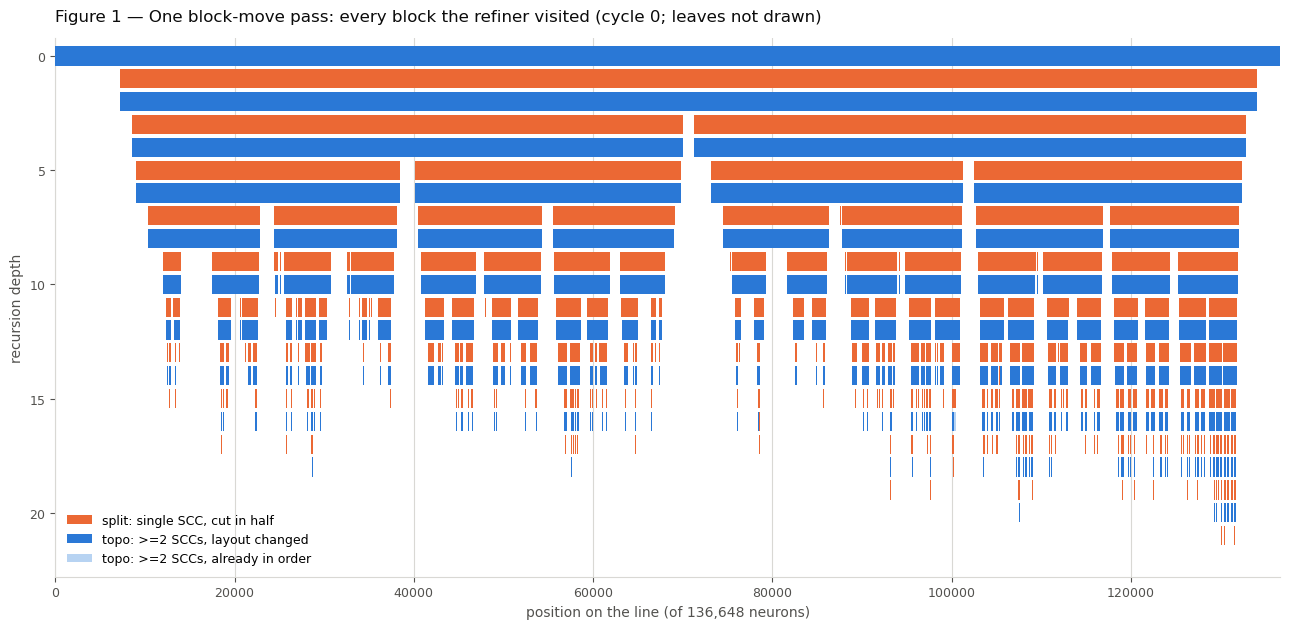

In [7]:
"""Figure 1 — recursion map of the first block-move pass."""
fig, ax = plt.subplots(figsize=(13.0, 6.4))

d_max = int(ev0["depth"].max())
groups = [
    ("split: single SCC, cut in half", CONFIG["c_split"],
     is_split, 4),
    ("topo: >=2 SCCs, layout changed", CONFIG["c_topo"],
     is_topo & (ev0["moved"] > 0), 3),
    ("topo: >=2 SCCs, already in order", CONFIG["c_topo_still"],
     is_topo & (ev0["moved"] == 0), 2),
]
for label, color, mask, z in groups:
    spans = list(zip(ev0["lo"][mask], ev0["size"][mask]))
    for depth in np.unique(ev0["depth"][mask]):
        at = ev0["depth"][mask] == depth
        ax.broken_barh([s for s, keep in zip(spans, at) if keep],
                       (depth - 0.42, 0.84), facecolors=color, linewidth=0, zorder=z)
    ax.broken_barh([], (0, 0), facecolors=color, label=label)   # one legend entry

ax.set_xlim(0, trace_meta["n_nodes"])
ax.set_ylim(d_max + 0.8, -0.8)                                   # depth 0 on top
ax.set_xlabel("position on the line (of %s neurons)" % format(trace_meta["n_nodes"], ","))
ax.set_ylabel("recursion depth")
ax.set_title("Figure 1 — One block-move pass: every block the refiner visited "
             "(cycle 0; leaves not drawn)", loc="left", pad=12)
ax.legend(loc="lower left", fontsize=9)   # the lower-left region of the map is empty
style_axes(ax, ygrid=False)
ax.grid(axis="x", color=CONFIG["grid"], linewidth=0.8)

fig.tight_layout()
save_fig(fig, "stage4_fig1_recursion_map.png")
plt.show()

### Figure 2 — how big the pieces are

Left: the sizes of the **blocks** the refiner visited (every rectangle of figure 1).
Right: the sizes of the **SCCs** it found when a block decomposed. Both axes are
logarithmic — the distributions span five orders of magnitude, from the giant
component down to single neurons.

saved: notebooks/outputs/stage4_fig2_sizes.png


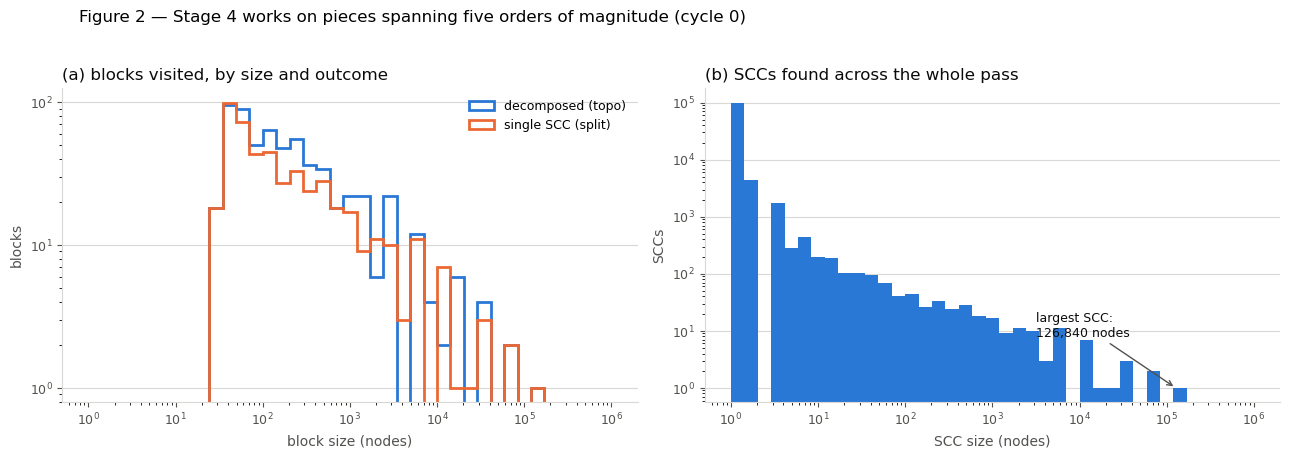

SCCs of exactly 1 node: 100,228 of 108,187 (92.6%) — most of any decomposition is dust;
the refiner's work is deciding where the FEW big components go.


In [8]:
"""Figure 2 — size distributions of blocks visited and SCCs found (cycle 0)."""
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13.0, 4.4))

work = ev0["kind"] != KIND_LEAF
log_bins = np.logspace(0, np.ceil(np.log10(ev0["size"][work].max())), 40)

axL.hist(ev0["size"][is_topo], bins=log_bins, color=CONFIG["c_topo"],
         label="decomposed (topo)", histtype="step", linewidth=2.0)
axL.hist(ev0["size"][is_split], bins=log_bins, color=CONFIG["c_split"],
         label="single SCC (split)", histtype="step", linewidth=2.0)
axL.set_xscale("log"); axL.set_yscale("log")
axL.set_xlabel("block size (nodes)")
axL.set_ylabel("blocks")
axL.set_title("(a) blocks visited, by size and outcome", loc="left")
axL.legend(fontsize=9)
style_axes(axL)

giant = int(scc_sizes0.max())
axR.hist(scc_sizes0, bins=log_bins, color=CONFIG["c_topo"])
axR.set_xscale("log"); axR.set_yscale("log")
axR.set_xlabel("SCC size (nodes)")
axR.set_ylabel("SCCs")
axR.set_title("(b) SCCs found across the whole pass", loc="left")
axR.annotate("largest SCC:\n%s nodes" % format(giant, ","),
             xy=(giant, 1), xytext=(giant / 40, 8), fontsize=9, color=CONFIG["ink"],
             arrowprops=dict(arrowstyle="->", color=CONFIG["ink_soft"], linewidth=1.0))
style_axes(axR)

fig.suptitle("Figure 2 — Stage 4 works on pieces spanning five orders of magnitude "
             "(cycle 0)", x=0.065, ha="left", fontsize=12, y=1.03)
fig.tight_layout()
save_fig(fig, "stage4_fig2_sizes.png")
plt.show()

n_tiny = int((scc_sizes0 == 1).sum())
print("SCCs of exactly 1 node: %s of %s (%.1f%%) — most of any decomposition is dust;"
      % (format(n_tiny, ","), format(len(scc_sizes0), ","),
         100.0 * n_tiny / len(scc_sizes0)))
print("the refiner's work is deciding where the FEW big components go.")

---

## 7. Across all 77 cycles: which half earns the score?

Each cycle is two half-steps: the block move, then the short sift. Since the block
move is monotone by construction and the sift chains from its output, the per-cycle
gain splits cleanly into a **block share** and a **sift share**.

saved: notebooks/outputs/stage4_fig3_attribution.png


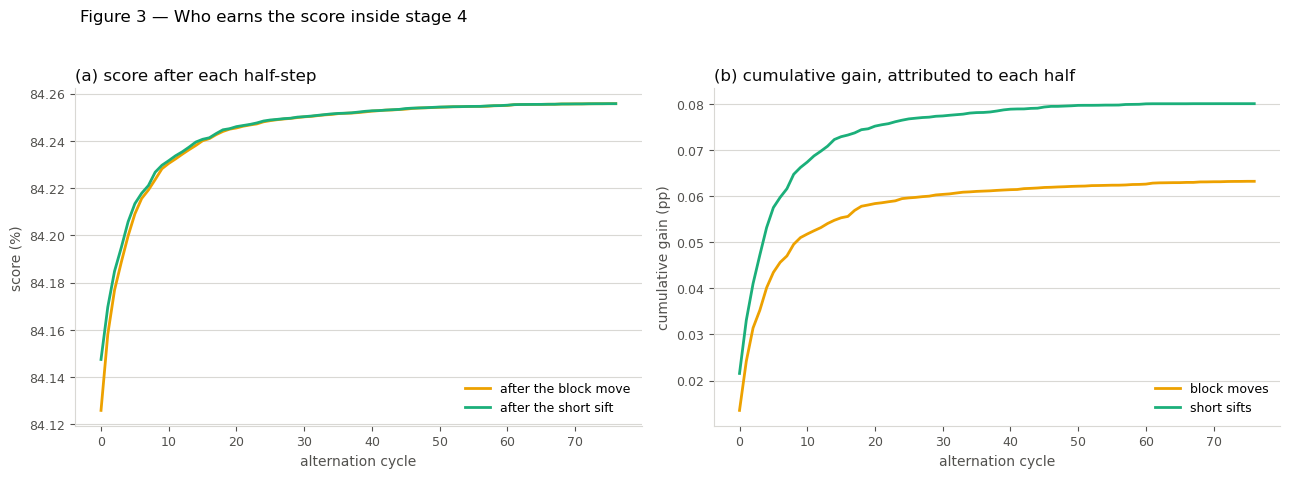

total stage-4 gain: +0.14328 pp = block moves +0.06322 pp + short sifts +0.08006 pp
first 10 cycles carry 82% of the whole stage's gain
time split: block moves 97 s, sifts 429 s


In [9]:
"""Figure 3 — score trajectory and gain attribution across the alternation."""
n_cyc = trace_meta["alt_cycles"]
cyc = np.arange(n_cyc)
end_prev = np.concatenate([[trace_meta["input_pct"]], trace["after_sift_pct"][:-1]])
gain_scc = trace["after_scc_pct"] - end_prev              # >= 0: the block move is monotone
gain_sift = trace["after_sift_pct"] - trace["after_scc_pct"]

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13.0, 4.6))

axL.plot(cyc, trace["after_scc_pct"], color=CONFIG["c_block"], linewidth=2.0,
         label="after the block move")
axL.plot(cyc, trace["after_sift_pct"], color=CONFIG["c_sift"], linewidth=2.0,
         label="after the short sift")
axL.set_xlabel("alternation cycle")
axL.set_ylabel("score (%)")
axL.set_title("(a) score after each half-step", loc="left")
axL.legend(fontsize=9, loc="lower right")
style_axes(axL)

axR.plot(cyc, np.cumsum(gain_scc), color=CONFIG["c_block"], linewidth=2.0,
         label="block moves")
axR.plot(cyc, np.cumsum(gain_sift), color=CONFIG["c_sift"], linewidth=2.0,
         label="short sifts")
axR.set_xlabel("alternation cycle")
axR.set_ylabel("cumulative gain (pp)")
axR.set_title("(b) cumulative gain, attributed to each half", loc="left")
axR.legend(fontsize=9, loc="lower right")
style_axes(axR)

fig.suptitle("Figure 3 — Who earns the score inside stage 4", x=0.065, ha="left",
             fontsize=12, y=1.03)
fig.tight_layout()
save_fig(fig, "stage4_fig3_attribution.png")
plt.show()

tot_scc, tot_sift = gain_scc.sum(), gain_sift.sum()
print("total stage-4 gain: %+0.5f pp = block moves %+0.5f pp + short sifts %+0.5f pp"
      % (tot_scc + tot_sift, tot_scc, tot_sift))
print("first 10 cycles carry %.0f%% of the whole stage's gain"
      % (100 * (np.cumsum(gain_scc + gain_sift)[9] / (tot_scc + tot_sift))))
half_t = trace["t_scc_s"].sum(), trace["t_sift_s"].sum()
print("time split: block moves %.0f s, sifts %.0f s" % half_t)

**Why keep alternating if the halves' own gains collapse?** Because each half
*re-opens* moves for the other: the sift changes node positions, which changes the
block boundaries and the SCC structure the next block pass sees; the block pass
relocates whole components, which gives the sift fresh single-node moves. The
activity plot below shows this exchange staying alive long after the score has
visibly flattened — and the split fraction cycling (period 5) is visible as the
regular ripple in the block half's activity.

saved: notebooks/outputs/stage4_fig4_activity.png


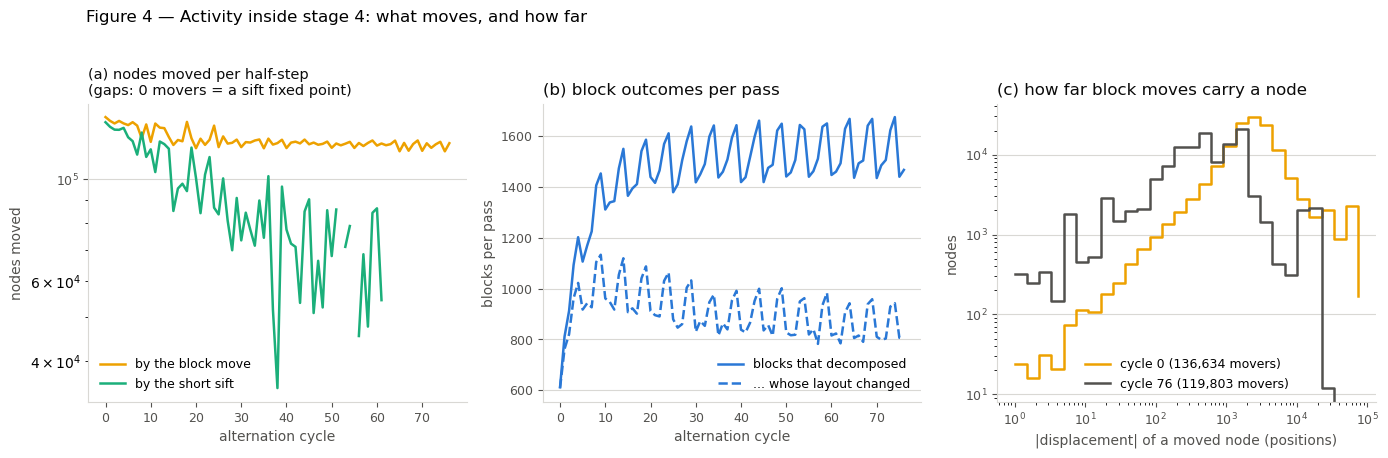

median |displacement| in cycle 0: 2340 positions; in cycle 76: 522
share of block passes that changed at least one block: 100%


In [10]:
"""Figure 4 — activity across cycles: nodes moved, blocks changed, distance travelled."""
fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.4))

axA, axB, axC = axes

axA.plot(cyc, np.where(trace["moved_scc"] > 0, trace["moved_scc"], np.nan),
         color=CONFIG["c_block"], linewidth=1.8, label="by the block move")
axA.plot(cyc, np.where(trace["moved_sift"] > 0, trace["moved_sift"], np.nan),
         color=CONFIG["c_sift"], linewidth=1.8, label="by the short sift")
axA.set_yscale("log")
axA.set_xlabel("alternation cycle")
axA.set_ylabel("nodes moved")
axA.set_title("(a) nodes moved per half-step\n(gaps: 0 movers = a sift fixed point)",
              loc="left", fontsize=10.5)
axA.legend(fontsize=9)
style_axes(axA)

axB.plot(cyc, trace["n_topo_blocks"], color=CONFIG["c_topo"], linewidth=1.8,
         label="blocks that decomposed")
axB.plot(cyc, trace["n_reordered"], color=CONFIG["c_topo"], linewidth=1.8,
         linestyle="--", label="... whose layout changed")
axB.set_xlabel("alternation cycle")
axB.set_ylabel("blocks per pass")
axB.set_title("(b) block outcomes per pass", loc="left")
axB.legend(fontsize=9)
style_axes(axB)

d0 = np.abs(trace["disp_scc_%02d" % DEEP[0]])
dZ = np.abs(trace["disp_scc_%02d" % DEEP[-1]])
disp_bins = np.logspace(0, np.log10(max(d0.max(), dZ.max()) + 1), 30)
for d, cyc_id, color in [(d0[d0 > 0], DEEP[0], CONFIG["c_block"]),
                         (dZ[dZ > 0], DEEP[-1], CONFIG["ink_soft"])]:
    h, edges = np.histogram(d, bins=disp_bins)
    axC.step(edges[:-1], h, where="post", linewidth=1.8, color=color,
             label="cycle %d (%s movers)" % (cyc_id, format(len(d), ",")))
axC.set_xscale("log"); axC.set_yscale("log")
axC.set_xlabel("|displacement| of a moved node (positions)")
axC.set_ylabel("nodes")
axC.set_title("(c) how far block moves carry a node", loc="left")
axC.legend(fontsize=9)
style_axes(axC)

fig.suptitle("Figure 4 — Activity inside stage 4: what moves, and how far",
             x=0.065, ha="left", fontsize=12, y=1.03)
fig.tight_layout()
save_fig(fig, "stage4_fig4_activity.png")
plt.show()

print("median |displacement| in cycle %d: %.0f positions; in cycle %d: %.0f"
      % (DEEP[0], np.median(d0[d0 > 0]) if (d0 > 0).any() else 0,
         DEEP[-1], np.median(dZ[dZ > 0]) if (dZ > 0).any() else 0))
print("share of block passes that changed at least one block: %.0f%%"
      % (100.0 * (trace["n_reordered"] > 0).mean()))

---

## 9. Where on the line the movement happens

Each row is one alternation cycle; each column a stretch of the line (128 bins over
the 136,648 positions). The colour counts how many nodes each half picked up from
that stretch in that cycle — the two panels share one colour scale, so they are
directly comparable.

The two halves look completely different. The **block half** repaints nearly the
entire span of the giant SCC every cycle: a topological re-layout shifts almost
every node in the block by at least a little, whether or not that changes any edge
direction (positions outside the giant component go quiet after the first cycles —
their small SCCs are sorted once and stay sorted). The **sift half** is selective:
it touches fewer and fewer specific places, until whole cycles pass with no mover
at all. Density of movement is therefore *not* density of improvement — compare
figure 3(b).

saved: notebooks/outputs/stage4_fig5_where.png


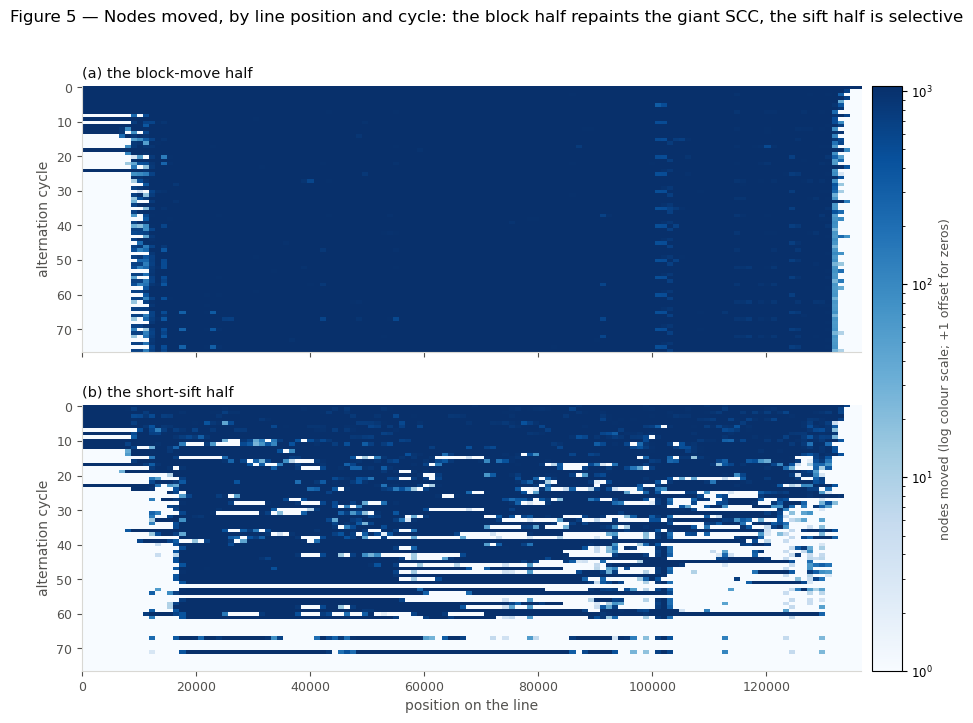

block half: stretches ever touched 128 of 128;  movement per cycle 136,634 -> 119,803 nodes
sift half: stretches ever touched 126 of 128;  movement per cycle 133,139 -> 0 nodes


In [11]:
"""Figure 5 — movement density: position on the line x alternation cycle, per half."""
from matplotlib.colors import LogNorm

heat_b = trace["heat_scc"].astype(float)
heat_s = trace["heat_sift"].astype(float)
norm = LogNorm(vmin=1.0, vmax=max(heat_b.max(), heat_s.max(), 2.0))

fig, (axT, axB) = plt.subplots(2, 1, figsize=(12.0, 7.6), sharex=True)
for ax, heat, label in [(axT, heat_b, "(a) the block-move half"),
                        (axB, heat_s, "(b) the short-sift half")]:
    im = ax.imshow(heat + 1.0, aspect="auto", origin="upper", cmap="Blues", norm=norm,
                   extent=(0, trace_meta["n_nodes"], n_cyc - 0.5, -0.5))
    ax.set_ylabel("alternation cycle")
    ax.set_title(label, loc="left", fontsize=10.5)
    style_axes(ax, ygrid=False)
axB.set_xlabel("position on the line")

fig.suptitle("Figure 5 — Nodes moved, by line position and cycle: the block half "
             "repaints the giant SCC, the sift half is selective",
             x=0.065, ha="left", fontsize=12, y=0.98)
cb = fig.colorbar(im, ax=[axT, axB], pad=0.012)
cb.set_label("nodes moved (log colour scale; +1 offset for zeros)", fontsize=9)
cb.ax.tick_params(labelsize=8.5)

save_fig(fig, "stage4_fig5_where.png")
plt.show()

for name, heat in [("block half", heat_b), ("sift half", heat_s)]:
    col_tot = heat.sum(axis=0)
    print("%s: stretches ever touched %3d of %d;  movement per cycle %s -> %s nodes"
          % (name, (col_tot > 0).sum(), CONFIG["pos_bins"],
             format(int(heat[0].sum()), ","), format(int(heat[-1].sum()), ",")))

---

## 10. What this notebook establishes — and what it does not

**Established, on this machine's run** (all figures above are one deterministic
trace from the cached input vector):

* The stage's structure problem is **one giant SCC** holding ~93% of the neurons:
  the top-level decomposition is nearly free of usable structure, and everything
  interesting happens after the splitter cuts into the giant component — which is
  precisely the design rationale recorded in `mfas/refine/scc_recursive.py`.
* Most SCCs any decomposition finds are **single nodes**; the refiner's real work
  is placing the few large components.
* The score is earned mostly in the **first cycles**, but the alternation keeps
  exchanging opportunities between the two move classes long after the score curve
  flattens — visible as sustained node movement (figure 4a) and as the period-5
  ripple of the split-fraction schedule (figure 4b).
* The two halves are **asymmetric in opposite directions**: on this trace the short
  sifts bank slightly more of the stage's gain while costing most of its wall-clock,
  and the block moves are the cheap half — but each half's gain exists only because
  the other keeps re-opening moves for it, so the split is an accounting of *where*
  the score lands, not of causal credit.
* **Movement is not improvement.** In late cycles the sift reaches genuine fixed
  points (zero movers) while the block half still relocates >100k nodes per pass for
  ~0.0001 pp — a topological re-layout may shuffle positions without flipping edges.
* Block moves carry nodes **long distances** (median thousands of positions early
  on) — consistent with the project's meta-rule M4 (the recoverable weight is
  long-range, which is why rank-window local search found nothing).

**Not established here:**

* Nothing about the registered champion's exact numbers — stage 2 ran on Apple MPS,
  so the stage-4 input differs slightly from the CUDA champion records. Champion
  claims live in `results/*.json` + `autoresearch/sota.json` only.
* Nothing statistical — this is one (deterministic) trace, dissected, not a sample.

### Reproducing this notebook

```bash
python notebooks/create_stage4_inside.py            # regenerate
jupyter nbconvert --to notebook --execute --inplace \
    notebooks/stage4_inside.ipynb                   # first run ~15-25 min, cached: seconds
```

Delete `notebooks/outputs/stage4_inside_trace.npz` to re-run stage 4 from the cached
input; delete `notebooks/outputs/stage4_input_rank.npy` as well to re-run stages 1–3.